In [1]:
# Titanic EDA - basic exploration
# Dataset: https://www.kaggle.com/c/titanic/data (train.csv)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [13]:
df = pd.read_csv(r"C:\Users\syin\Downloads\Titanic_dataset\Titanic-Dataset.csv")

In [14]:
# ---- 1. First look at the data ----
print(df.shape)
print(df.head())
print(df.info())
print(df.describe())


(891, 12)
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   NaN    

In [15]:
# ---- 2. Check missing values ----
print(df.isnull().sum())


PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


Survived
0    549
1    342
Name: count, dtype: int64


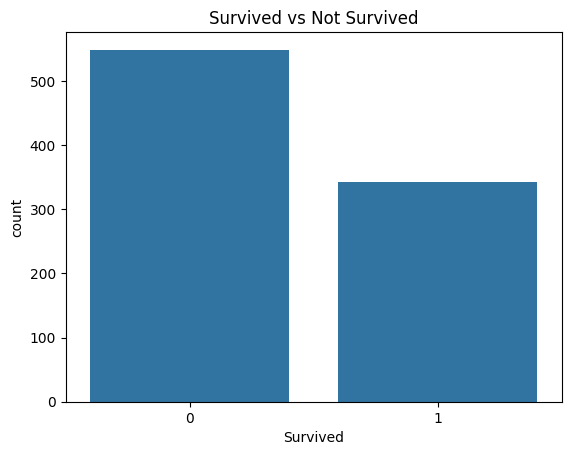

In [16]:
# Age, Cabin, Embarked have missing values
# Cabin has too many missing values, might drop it later

# ---- 3. Target variable ----
print(df["Survived"].value_counts())

sns.countplot(x="Survived", data=df)
plt.title("Survived vs Not Survived")
plt.show()


Sex
female    0.742038
male      0.188908
Name: Survived, dtype: float64


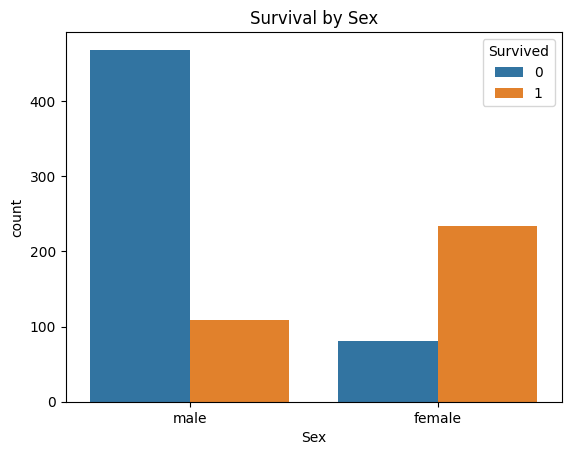

In [17]:
# ---- 4. Survival by sex ----
print(df.groupby("Sex")["Survived"].mean())

sns.countplot(x="Sex", hue="Survived", data=df)
plt.title("Survival by Sex")
plt.show()

# females survived way more than males


Pclass
1    0.629630
2    0.472826
3    0.242363
Name: Survived, dtype: float64


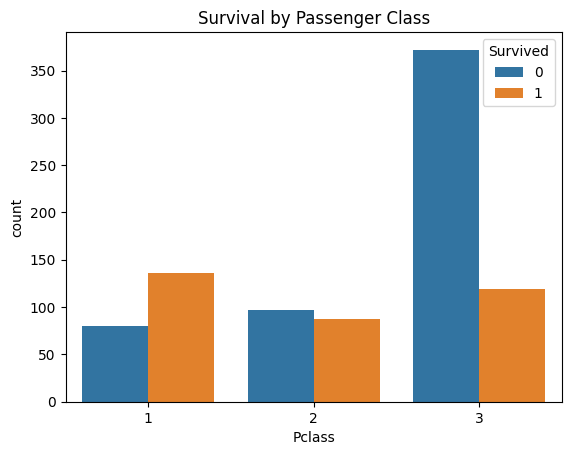

In [18]:
# ---- 5. Survival by passenger class ----
print(df.groupby("Pclass")["Survived"].mean())

sns.countplot(x="Pclass", hue="Survived", data=df)
plt.title("Survival by Passenger Class")
plt.show()

# 1st class survived more than 3rd class, makes sense


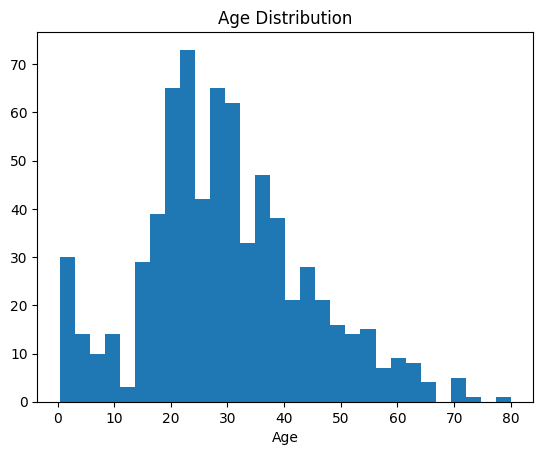

In [19]:
# ---- 6. Age distribution ----
plt.hist(df["Age"].dropna(), bins=30)
plt.title("Age Distribution")
plt.xlabel("Age")
plt.show()


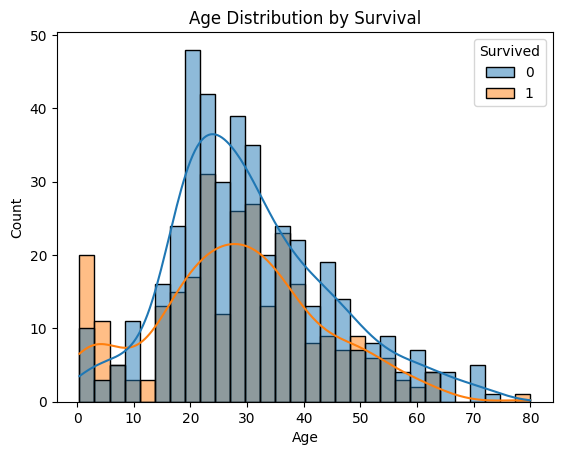

In [20]:
# ---- 7. Age vs survival ----
sns.histplot(data=df, x="Age", hue="Survived", bins=30, kde=True)
plt.title("Age Distribution by Survival")
plt.show()


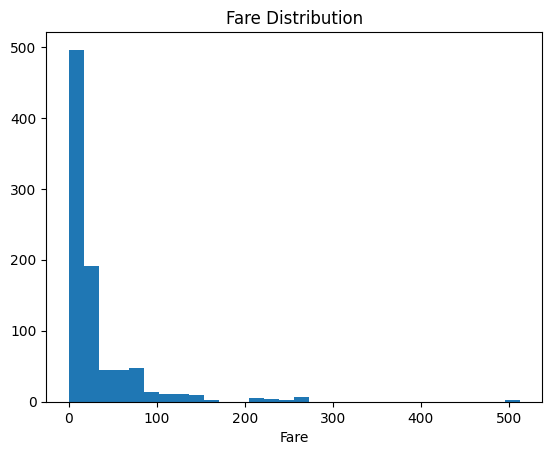

In [21]:
# ---- 8. Fare distribution ----
plt.hist(df["Fare"], bins=30)
plt.title("Fare Distribution")
plt.xlabel("Fare")
plt.show()

# fare is very skewed, few people paid a lot


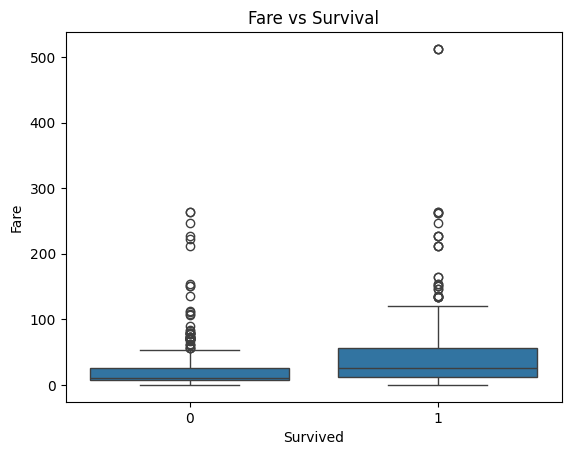

In [22]:
# ---- 9. Fare vs survival ----
sns.boxplot(x="Survived", y="Fare", data=df)
plt.title("Fare vs Survival")
plt.show()


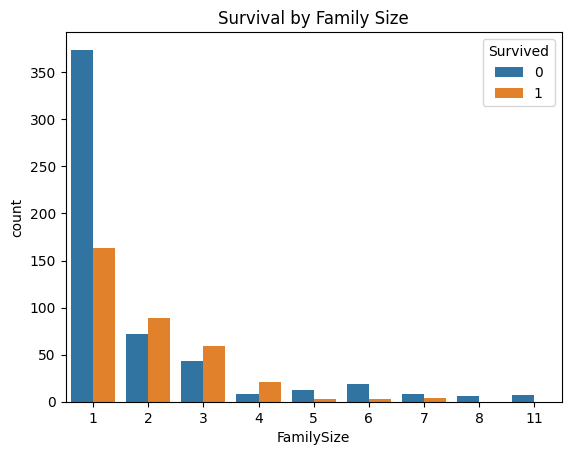

In [23]:
# ---- 10. Family size (SibSp + Parch) ----
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1

sns.countplot(x="FamilySize", hue="Survived", data=df)
plt.title("Survival by Family Size")
plt.show()


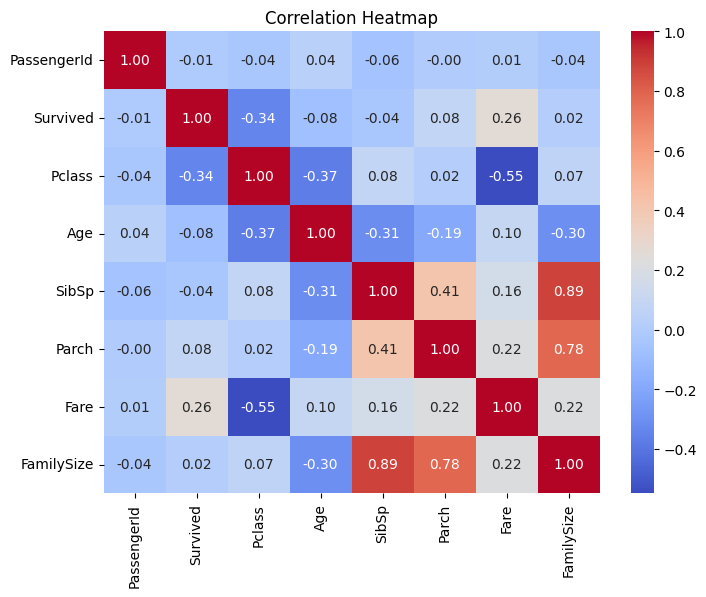

In [24]:
# ---- 11. Correlation heatmap ----
numeric_df = df.select_dtypes(include=np.number)
corr = numeric_df.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

# Pclass and Fare have decent correlation with Survived
